# PROYEK KLASIFIKASI GAMBAR: INTEL IMAGE
@hannazz

## 01. IMPORT LIBRARY

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random
import time
from PIL import Image
from collections import Counter
from pathlib import Path

# Kaggle
# !pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print(path)

# Modeling dataset
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf

# Konversi model
import shutil
from google.colab import files as colab_files


Using Colab cache for faster access to the 'intel-image-classification' dataset.
/kaggle/input/intel-image-classification


In [20]:
# PATH DIRECOTORY (vscode-jupyter)
# DATASET_TRAIN_PATH = "Intel_Dataset/seg_train"
# DATASET_TEST_PATH = "Intel_Dataset/seg_test"

# PATH (google colab)
for root, dirs, _ in os.walk(path):
    print(root, dirs[:6])
    if root.count(os.sep) - path.count(os.sep) >= 2: break

DATASET_TRAIN_PATH = os.path.join(path, "seg_train", "seg_train")
DATASET_TEST_PATH  = os.path.join(path, "seg_test",  "seg_test")
DATASET_PRED_PATH = os.path.join(path, "seg_pred", "seg_pred")

# CONFIGURATION
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

print("TensorFlow Colab:", tf.__version__)


/kaggle/input/intel-image-classification ['seg_train', 'seg_pred', 'seg_test']
/kaggle/input/intel-image-classification/seg_train ['seg_train']
/kaggle/input/intel-image-classification/seg_train/seg_train ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']
TensorFlow Colab: 2.21.0


## 02. DATA PREPARATION

Dataset diambil dari [Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification/data). Publisher asli oleh [Intel pada analyticsvidhya.com]( https://datahack.analyticsvidhya.com)

Dataset berisi sekitar 25 ribu gambar pemandangan alam dari berbagai penjuru dunia, berukuran 150×150 piksel, dengan 6 kategori, yaitu:
- buildings
- forest
- glacier
- mountain
- sea
- street

Dataset dikelompokkan dalam 3 folder: <br>
├── `seg_pred` --> berisi sekitar 7 ribu gambar.<br>
├── `seg_test` --> berisi sekitar 3 ribu gambar.<br>
└── `seg_train` --> berisi sekitar 14 ribu gambar.<br>


### **Data Loading**

### 🟩 INFO DATA

In [21]:
def hitung_per_kelas(path):
    """Hitung jumlah gambar di setiap subfolder (satu subfolder = satu kelas)."""
    hasil = {}
    for kelas in sorted(os.listdir(path)):
        folder = os.path.join(path, kelas)
        if os.path.isdir(folder):
            hasil[kelas] = sum(f.lower().endswith(IMAGE_EXTS) for f in os.listdir(folder))
    return hasil

train_counts = hitung_per_kelas(DATASET_TRAIN_PATH)
test_counts = hitung_per_kelas(DATASET_TEST_PATH)
class_names = list(train_counts.keys())
NUM_CLASSES = len(class_names)

df_counts = pd.DataFrame({
    "Train": train_counts,
    "Test": test_counts
    })

df_counts["Total"] = df_counts["Train"] + df_counts["Test"]
print("Jumlah gambar per kelas:")
print(df_counts)

print("\nTotal gambar train + test :", df_counts["Total"].sum())
print("Gambar training           :", df_counts["Train"].sum())
print("Gambar test               :", df_counts["Test"].sum())
print("Jumlah kelas              :", NUM_CLASSES)
print("Kelas                     :", class_names)


Jumlah gambar per kelas:
           Train  Test  Total
buildings   2191   437   2628
forest      2271   474   2745
glacier     2404   553   2957
mountain    2512   525   3037
sea         2274   510   2784
street      2382   501   2883

Total gambar train + test : 17034
Gambar training           : 14034
Gambar test               : 3000
Jumlah kelas              : 6
Kelas                     : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


### 🟩 VISUALISASI KELAS DATA

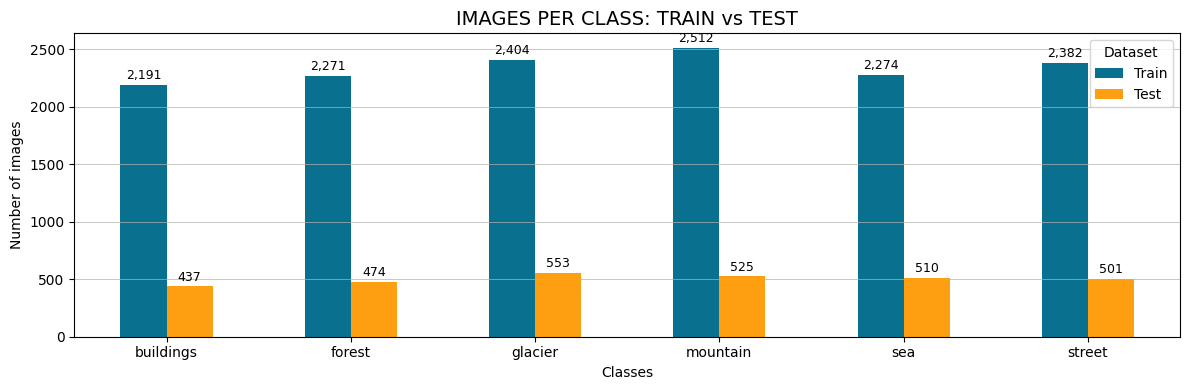

In [22]:
# Visualisasi jumlah gambar per kelas
fig, ax = plt.subplots(figsize=(12, 4))
df_counts[['Train', 'Test']].plot.bar(ax=ax, color=["#0A708F", "#FD9F11"], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", fontsize=9, padding=2)

ax.set_title('IMAGES PER CLASS: TRAIN vs TEST', fontsize=14)
ax.set_xlabel('Classes')
ax.set_ylabel('Number of images')
ax.legend(title='Dataset')
ax.yaxis.grid(linewidth=0.5)

plt.tight_layout()
plt.show()


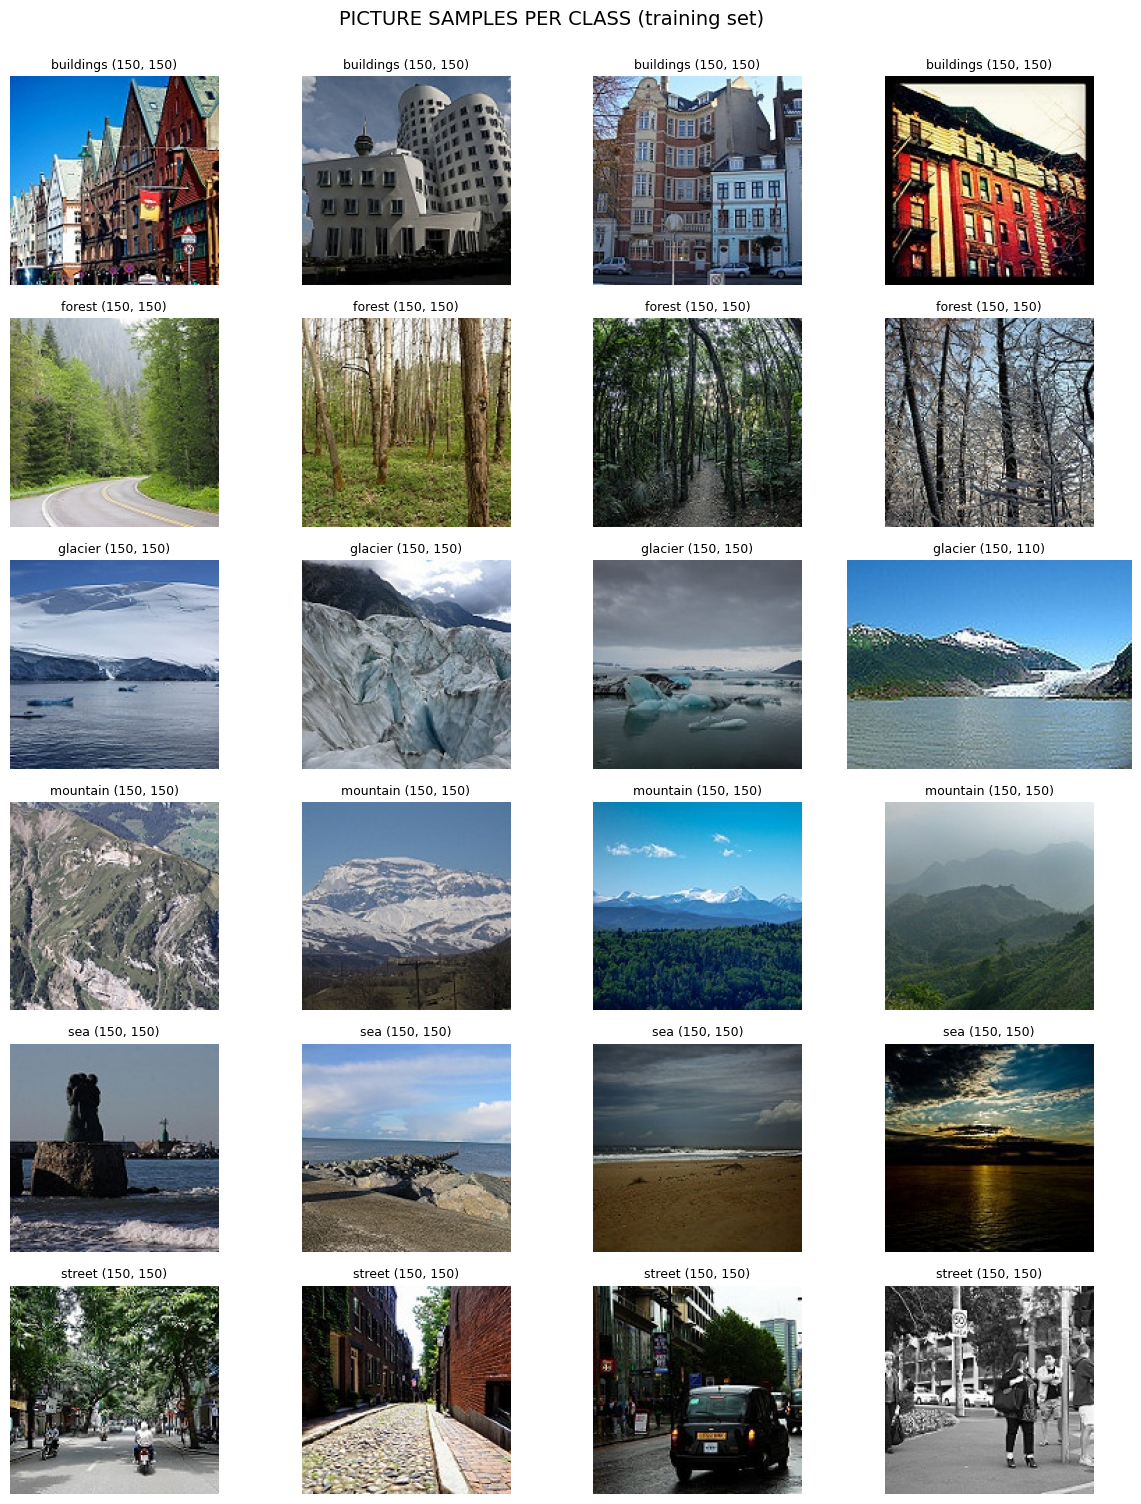

In [23]:
# Visualisasi sampel gambar tiap kelas (raw train set)
N_SAMPLE = 4

fig, ax = plt.subplots(NUM_CLASSES, N_SAMPLE, figsize=(3 * N_SAMPLE, 2.5 * len(class_names)))
for i, kelas in enumerate(class_names):
    folder = os.path.join(DATASET_TRAIN_PATH, kelas)
    files = [f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTS)]
    for j, fname in enumerate(random.sample(files, N_SAMPLE)):
        img = Image.open(os.path.join(folder, fname))
        ax[i, j].imshow(img)
        ax[i, j].set_title(f"{kelas} {img.size}", fontsize=9)
        ax[i, j].axis("off")

plt.suptitle("PICTURE SAMPLES PER CLASS (training set)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()


### **Data Preprocessing**

### 🟨 CEK RESOULUSI GAMBAR ASLI

In [24]:
def resolution_check(path):
    ukuran = Counter()
    for f in Path(path).rglob("*"):
        if f.suffix.lower() in IMAGE_EXTS:
            with Image.open(f) as im:
                ukuran[im.size] += 1
    return ukuran

res = resolution_check(DATASET_TRAIN_PATH) + resolution_check(DATASET_TEST_PATH)
print("Jumlah resolusi berbeda:", len(res))
print(res.most_common(10))


Jumlah resolusi berbeda: 32
[((150, 150), 16979), ((150, 113), 7), ((150, 135), 3), ((150, 111), 3), ((150, 141), 2), ((150, 144), 2), ((150, 134), 2), ((150, 131), 2), ((150, 143), 2), ((150, 81), 2)]


Gambar-gambar yang termuat dalam dataset baik untuk kebutuhan pelatihan dan pengujian model memiliki resolusi yang tidak seragam. Namun, frekuensi data gambar dengan resolusi **(150, 150)** paling tinggi dari resolusi lainnya. Resolusi tersebut menjadi patokan lewat `image_dataset_from_directory` untuk membuat dataset yang seragam.

### 🟨 SPLIT DATA

Folder training dibagi menjadi rasio **80:20** secara beruturut-turut untuk himpunanan **data training dan validation**. Kedua subset dibuat dengan `seed` sama agar pembagiannya dapat direproduksi. Pada folder test dibiarkan sama untuk kebutuhan testing model.

In [25]:
# Train 80% / Validation 20% dari seg_train; test memakai seg_test
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_TRAIN_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True
    )

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_TRAIN_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True
    )

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_TEST_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
    )

assert train_ds.class_names == class_names == test_ds.class_names
n_tr, n_va, n_te = len(train_ds.file_paths), len(val_ds.file_paths), len(test_ds.file_paths)
total = n_tr + n_va + n_te
print(f"\nTrain      : {n_tr} ({n_tr/total:.1%})")
print(f"Validation : {n_va}  ({n_va/total:.1%})")
print(f"Test       : {n_te}  ({n_te/total:.1%})")


Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.

Train      : 11228 (65.9%)
Validation : 2806  (16.5%)
Test       : 3000  (17.6%)


### 🟨 AUGMENTASI

In [26]:
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    ])


### 🟨 AUTOTUNE

In [27]:
AUTOTUNE = tf.data.AUTOTUNE
train_raw = train_ds
train_ds = train_ds.map(lambda x, y: (augment(x, training=True), y),
                        num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds  = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


### 🟨 CEK DIMENSI, TIPE DATA, PIKSEL GAMBAR DATA TRAIN

In [28]:
x, y = next(iter(train_ds))
print("Bentuk batch gambar :", x.shape)          # (32, 150, 150, 3)
print("Bentuk batch label  :", y.shape)          # (32, 6)
print("Tipe data           :", x.dtype)
print("Rentang piksel      :", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))


Bentuk batch gambar : (32, 150, 150, 3)
Bentuk batch label  : (32, 6)
Tipe data           : <dtype: 'float32'>
Rentang piksel      : 0.0 - 255.0


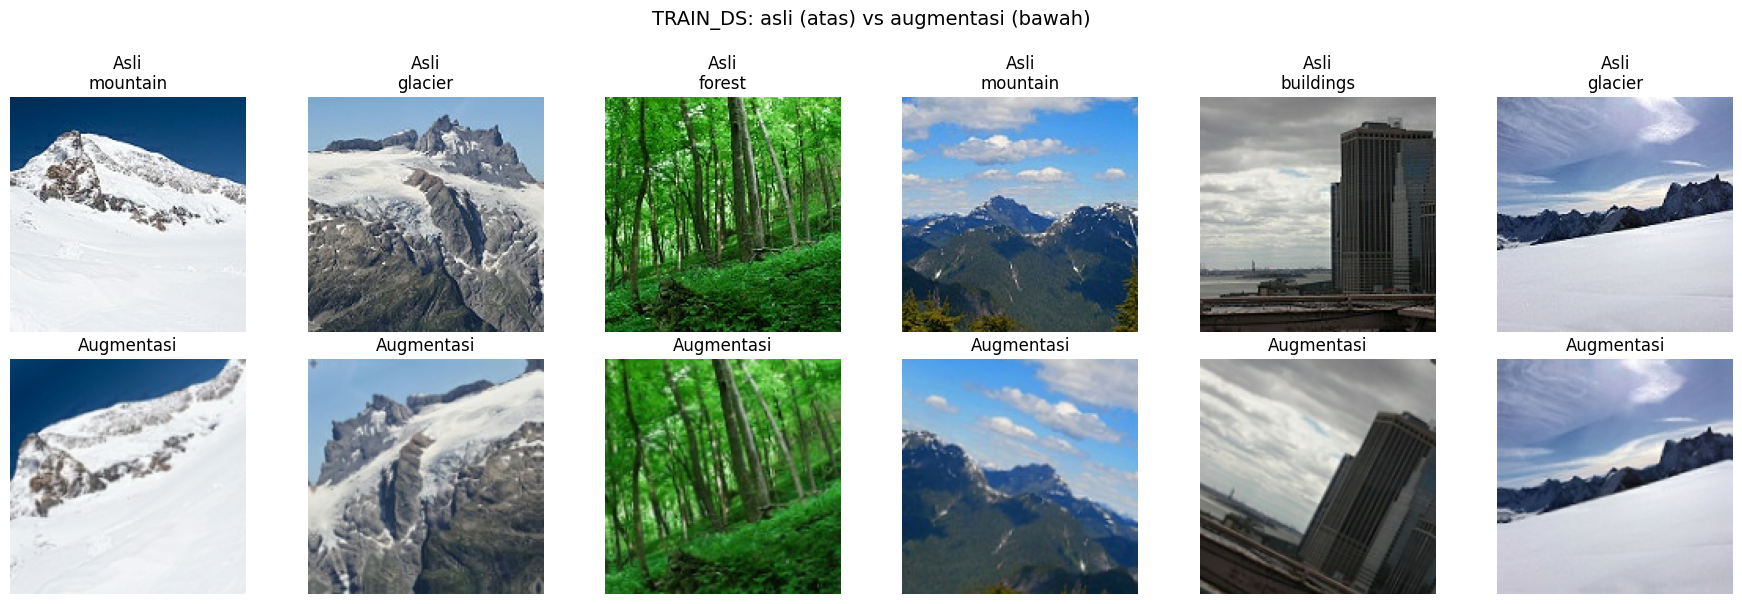

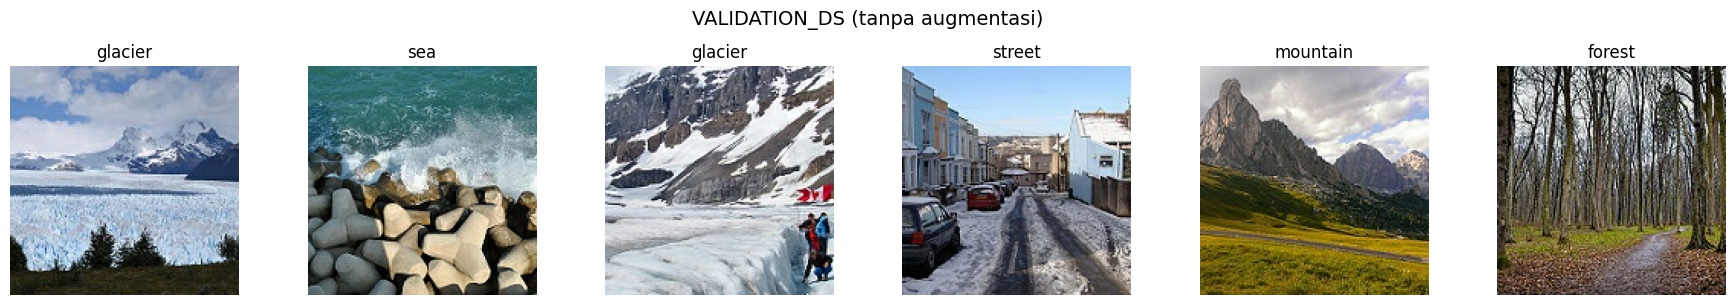

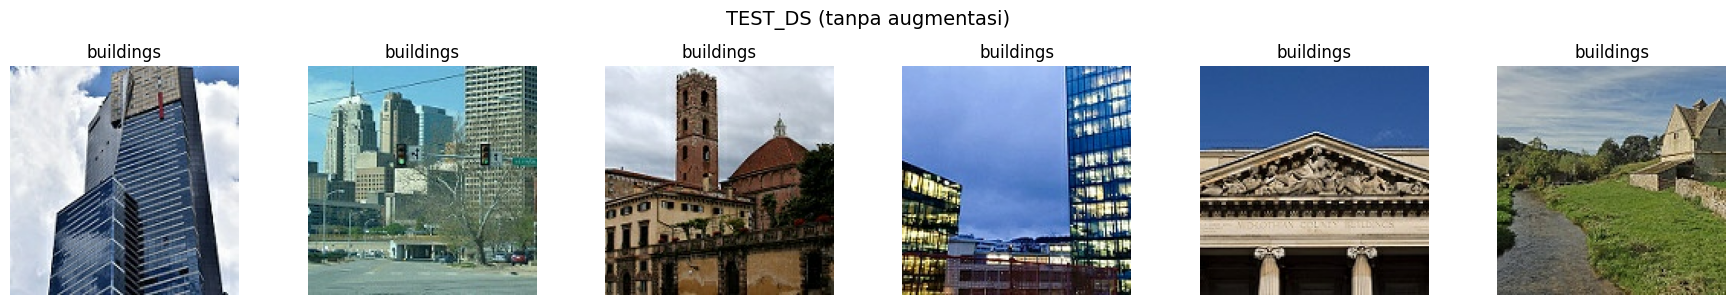

In [29]:
# Visualisasi data train, val, test pra-pemrosesan
def img_sample(ds, judul, n=6, compare=False):
    x, y = next(iter(ds))

    if compare:
        x_aug = augment(x, training=True)
        fig, ax = plt.subplots(2, n, figsize=(3 * n, 6))
        for i in range(n):
            kelas = class_names[y[i].numpy().argmax()]

            ax[0, i].imshow(x[i].numpy().astype("uint8"))
            ax[0, i].set_title(f"Asli\n{kelas}")
            ax[0, i].axis("off")

            ax[1, i].imshow(x_aug[i].numpy().astype("uint8"))
            ax[1, i].set_title("Augmentasi")
            ax[1, i].axis("off")
    else:
        # 1 baris, seperti kode awal
        fig, ax = plt.subplots(1, n, figsize=(3 * n, 3))
        for i in range(n):
            ax[i].imshow(x[i].numpy().astype("uint8"))
            ax[i].set_title(class_names[y[i].numpy().argmax()])
            ax[i].axis("off")

    fig.suptitle(judul, y=1.0, fontsize=14)
    plt.tight_layout()
    plt.show()

img_sample(train_raw, "TRAIN_DS: asli (atas) vs augmentasi (bawah)", compare=True)
img_sample(val_ds,  "VALIDATION_DS (tanpa augmentasi)")
img_sample(test_ds, "TEST_DS (tanpa augmentasi)")


## 03. MODELING

In [30]:
def build_cnn1():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=IMG_SIZE + (3,)),
        tf.keras.layers.Rescaling(1./255),

        tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D(),

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="cnn1")
    return model

cnn1_model = build_cnn1()
cnn1_model.summary()


Model: "cnn1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │     2,367,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,461,190 (9.39 MB)

 Trainable params: 2,461,190 (9.39 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
cnn1_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
    )

early_stop1 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
    )

start1 = time.perf_counter()
history1 = cnn1_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop1]
    )
time1 = time.perf_counter() - start1
print(f"Waktu pelatihan CNN awal: {time1:.2f} detik")


Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 64s 169ms/step - accuracy: 0.5720 - loss: 1.1007 - val_accuracy: 0.6497 - val_loss: 0.9258
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 56s 158ms/step - accuracy: 0.6763 - loss: 0.8689 - val_accuracy: 0.7263 - val_loss: 0.7363
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 57s 161ms/step - accuracy: 0.7154 - loss: 0.7673 - val_accuracy: 0.7295 - val_loss: 0.7530
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 56s 159ms/step - accuracy: 0.7489 - loss: 0.6935 - val_accuracy: 0.7470 - val_loss: 0.6950
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 82s 160ms/step - accuracy: 0.7629 - loss: 0.6380 - val_accuracy: 0.7830 - val_loss: 0.5991
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 57s 161ms/step - accuracy: 0.7845 - loss: 0.5916 - val_accuracy: 0.7573 - val_loss: 0.6752
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 167ms/step - accuracy: 0.7936 - loss: 0.5665 - val_accuracy: 0.8100 - val_loss: 0.5252
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 82s 167ms/step - accuracy: 0.8094 - loss: 0

## 04. EVALUATION + VISUALIZATION

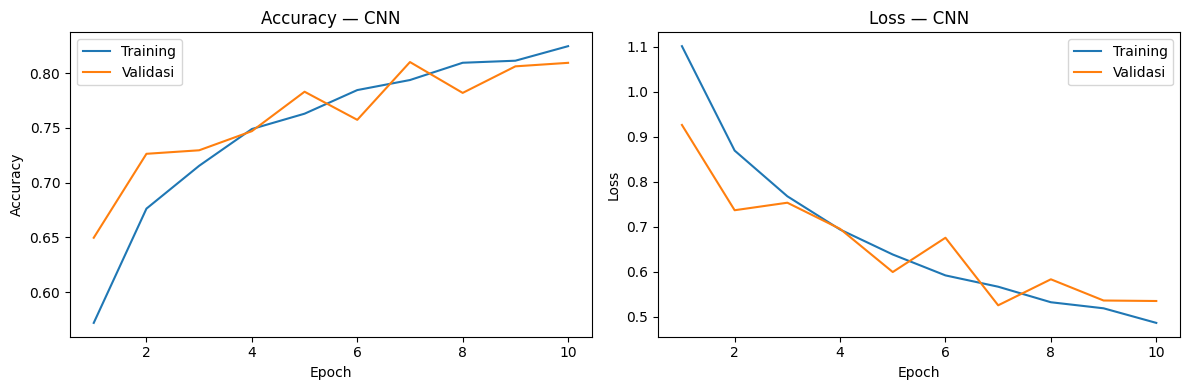

In [32]:
def plot_history(history, title):
    epochs = range(1, len(history.history["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(epochs, history.history["accuracy"], label="Training")
    ax[0].plot(epochs, history.history["val_accuracy"], label="Validasi")
    ax[0].set_title("Accuracy — " + title)
    ax[0].set_xlabel("Epoch")
    ax[0].set_ylabel("Accuracy")
    ax[0].legend()

    ax[1].plot(epochs, history.history["loss"], label="Training")
    ax[1].plot(epochs, history.history["val_loss"], label="Validasi")
    ax[1].set_title("Loss — " + title)
    ax[1].set_xlabel("Epoch")
    ax[1].set_ylabel("Loss")
    ax[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history1, "CNN")


### 🟦 EVALUASI TRAIN, VAL, TEST SET

In [33]:
train_loss, train_acc = cnn1_model.evaluate(train_ds, verbose=0)
val_loss, val_acc = cnn1_model.evaluate(val_ds, verbose=0)
test_loss, test_acc = cnn1_model.evaluate(test_ds, verbose=0)

print(f'CNN1 model - train acc: {train_acc:.4f} / train loss: {train_loss:.4f}')
print(f'CNN1 model - val acc  : {val_acc:.4f} / val loss  : {val_loss:.4f}')
print(f'CNN1 model - test acc : {test_acc:.4f} / test loss : {test_loss:.4f}')


CNN1 model - train acc: 0.8213 / train loss: 0.5057
CNN1 model - val acc  : 0.8100 / val loss  : 0.5252
CNN1 model - test acc : 0.8170 / test loss : 0.5388


In [ ]:
hasil = []
hasil.append({
    "Model": "CNN1 (baseline)",
    "Train Acc": train_acc, "Val Acc": val_acc, "Test Acc": test_acc,
    "Train Loss": train_loss, "Val Loss": val_loss, "Test Loss": test_loss
})


### 🟦 CLASSIFICATION REPORT & CONFUSION MATRIX

              precision    recall  f1-score   support

   buildings       0.76      0.79      0.78       437
      forest       0.96      0.92      0.94       474
     glacier       0.78      0.81      0.80       553
    mountain       0.79      0.73      0.76       525
         sea       0.83      0.79      0.81       510
      street       0.80      0.87      0.83       501

    accuracy                           0.82      3000
   macro avg       0.82      0.82      0.82      3000
weighted avg       0.82      0.82      0.82      3000



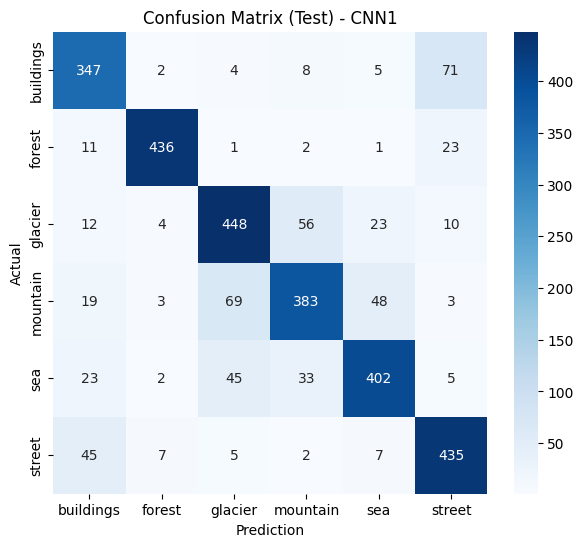

In [35]:
def evaluasi_detail(model, nama, dataset=test_ds, tampilkan_plot=True):
    y_true = np.concatenate([y.numpy().argmax(1) for _, y in dataset])
    y_pred = model.predict(dataset, verbose=0).argmax(1)

    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    if tampilkan_plot:
        plt.figure(figsize=(7, 6))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=class_names, yticklabels=class_names)
        plt.xlabel("Prediction")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix (Test) - {nama}")
        plt.show()

    return y_true, y_pred, cm

y_true1, y_pred1, cm1 = evaluasi_detail(cnn1_model, "CNN1")


### **Analisis**

- Model CNN mencapai akurasi **train 82,13%**, **validasi 81,00%**, dan **test 81,70%**. Model masih sedikit mengalami overfitting ringan.
- Sebanyak 69 kelas **mountain** diprediksi sebagai **glacier**, dan ada 56 gambar **glacier** diprediksi sebagai **mountain**. Kedua kelas ini memiliki nilai besar saling tertukar. Hal ini karena karakteristik pemandangan keduanya identik dengan salju dan es.
- Kelas **buildings** dan **street** juga mengalami kasus serupa saling tertukar. Hal ini karena jalanan yang hampir selalu memuat gedung, sehingga kesalahan prediksi cukup kuat terjadi.

## 05. MODEL IMPROVEMENT

### **Model**

Referensi: [TensorFlow | Transfer learning and fine-tuning](https://www.tensorflow.org/tutorials/images/transfer_learning)

### 🟪 FEATURE EXTRACTION (BASE MODEL)

In [ ]:
def build_cnn2():
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet"
    )
    base.trainable = False

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=IMG_SIZE + (3,)),
        tf.keras.layers.Rescaling(1./127.5, offset=-1),   # setara preprocess_input MobileNetV2
        base,                                             # output 5x5x1280

        tf.keras.layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),                   # 5x5 -> 2x2
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="cnn2")
    return model, base

cnn2_model, base_model = build_cnn2()
cnn2_model.summary()


/tmp/ipykernel_539/2352425448.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Model: "cnn2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 5, 5, 256)      │     2,949,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,208,902 (19.87 MB)

 Trainable params: 2,950,918 (11.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

**Compile Base Model**

In [ ]:
cnn2_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop2a = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

start2a = time.perf_counter()
history2a = cnn2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stop2a]
)
time2a = time.perf_counter() - start2a
print(f"Waktu pelatihan CNN2: {time2a:.2f} detik")


Epoch 1/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 79s 199ms/step - accuracy: 0.7913 - loss: 0.8870 - val_accuracy: 0.8756 - val_loss: 0.3353
Epoch 2/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 166ms/step - accuracy: 0.8521 - loss: 0.4199 - val_accuracy: 0.8909 - val_loss: 0.2942
Epoch 3/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 57s 161ms/step - accuracy: 0.8622 - loss: 0.3839 - val_accuracy: 0.8706 - val_loss: 0.3245
Epoch 4/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 57s 162ms/step - accuracy: 0.8680 - loss: 0.3671 - val_accuracy: 0.8909 - val_loss: 0.2885
Epoch 5/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 60s 171ms/step - accuracy: 0.8756 - loss: 0.3475 - val_accuracy: 0.9041 - val_loss: 0.2769
Epoch 6/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 81s 169ms/step - accuracy: 0.8774 - loss: 0.3384 - val_accuracy: 0.9091 - val_loss: 0.2610
Epoch 7/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 58s 165ms/step - accuracy: 0.8822 - loss: 0.3320 - val_accuracy: 0.9024 - val_loss: 0.2685
Epoch 8/25
351/351 ━━━━━━━━━━━━━━━━━━━━ 56s 159ms/step - accuracy: 0.8862 - loss: 0

### 🟪 FINE-TUNING

In [ ]:
base_model.trainable = True
fine_tune_at = len(base_model.layers) - 40

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# BatchNorm tetap beku agar statistik ImageNet tidak rusak
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Layer base yang dilatih:", sum(l.trainable for l in base_model.layers))


Layer base yang dilatih: 26


**Compile Fine-Tuning**

In [ ]:
cnn2_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop2b = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
reduce_lr2b = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

n_awal = len(history2a.history["loss"])
start2b = time.perf_counter()
history2b = cnn2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=n_awal + 20,
    initial_epoch=n_awal,
    callbacks=[early_stop2b, reduce_lr2b]
)

time2b = time.perf_counter() - start2b
time2 = time2a + time2b
print(f"Waktu total CNN3: {time2:.2f} detik")


Epoch 11/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 88s 209ms/step - accuracy: 0.8909 - loss: 0.3005 - val_accuracy: 0.9098 - val_loss: 0.2618 - learning_rate: 1.0000e-05
Epoch 12/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 58s 165ms/step - accuracy: 0.8996 - loss: 0.2738 - val_accuracy: 0.9088 - val_loss: 0.2662 - learning_rate: 1.0000e-05
Epoch 13/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 169ms/step - accuracy: 0.9037 - loss: 0.2646 - val_accuracy: 0.9134 - val_loss: 0.2498 - learning_rate: 1.0000e-05
Epoch 14/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 81s 165ms/step - accuracy: 0.9087 - loss: 0.2535 - val_accuracy: 0.9130 - val_loss: 0.2528 - learning_rate: 1.0000e-05
Epoch 15/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.9023 - loss: 0.2575
Epoch 15: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
351/351 ━━━━━━━━━━━━━━━━━━━━ 57s 163ms/step - accuracy: 0.9078 - loss: 0.2483 - val_accuracy: 0.9073 - val_loss: 0.2613 - learning_rate: 1.0000e-05
Epoch 16/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 60s 

### **Evaluation & Visualization**

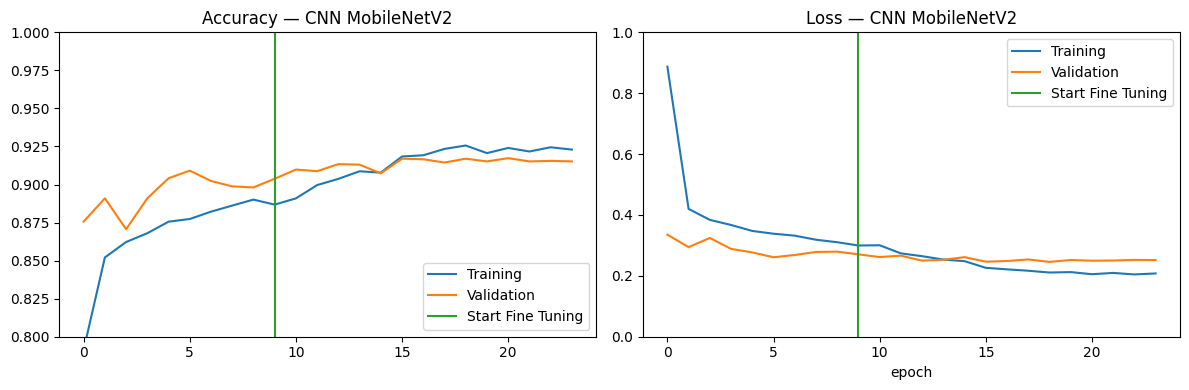

In [ ]:
accx      = history2a.history["accuracy"]      + history2b.history["accuracy"]
val_accx  = history2a.history["val_accuracy"]  + history2b.history["val_accuracy"]
lossx     = history2a.history["loss"]          + history2b.history["loss"]
val_lossx = history2a.history["val_loss"]      + history2b.history["val_loss"]

init_epochs = len(history2a.history["loss"])
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(accx, label="Training")
plt.plot(val_accx, label="Validation")
plt.ylim([0.8, 1])
plt.plot([init_epochs - 1, init_epochs - 1], plt.ylim(), label="Start Fine Tuning")
plt.legend(loc="lower right")
plt.title("Accuracy — CNN MobileNetV2")

plt.subplot(1, 2, 2)
plt.plot(lossx, label="Training")
plt.plot(val_lossx, label="Validation")
plt.ylim([0, 1.0])
plt.plot([init_epochs - 1, init_epochs - 1], plt.ylim(), label="Start Fine Tuning")
plt.legend(loc="upper right")
plt.title("Loss — CNN MobileNetV2")
plt.xlabel("epoch")

plt.tight_layout()
plt.show()


In [41]:
train2_loss, train2_acc = cnn2_model.evaluate(train_ds, verbose=0)
val2_loss, val2_acc = cnn2_model.evaluate(val_ds, verbose=0)
test2_loss, test2_acc = cnn2_model.evaluate(test_ds, verbose=0)

print(f'CNN2 model - train acc: {train2_acc:.4f} / train loss: {train2_loss:.4f}')
print(f'CNN2 model - val acc  : {val2_acc:.4f} / val loss  : {val2_loss:.4f}')
print(f'CNN2 model - test acc : {test2_acc:.4f} / test loss : {test2_loss:.4f}')


CNN2 model - train acc: 0.9340 / train loss: 0.1752
CNN2 model - val acc  : 0.9170 / val loss  : 0.2458
CNN2 model - test acc : 0.9157 / test loss : 0.2331


### 🟪 CLASSIFICATION REPORT & CONFUSION MATRIX

              precision    recall  f1-score   support

   buildings       0.89      0.96      0.92       437
      forest       1.00      0.99      0.99       474
     glacier       0.86      0.87      0.87       553
    mountain       0.89      0.83      0.86       525
         sea       0.92      0.96      0.94       510
      street       0.95      0.90      0.92       501

    accuracy                           0.92      3000
   macro avg       0.92      0.92      0.92      3000
weighted avg       0.92      0.92      0.92      3000



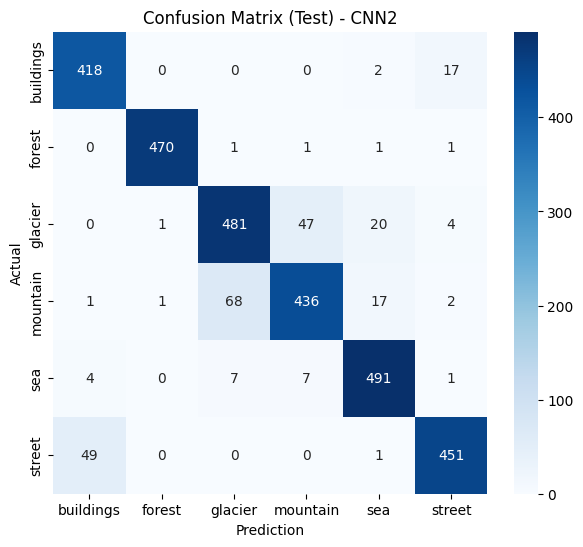

In [ ]:
y_true2, y_pred2, cm2 = evaluasi_detail(cnn2_model, "CNN2")


### 🟪 KOMPARASI MODEL CNN AWAL DAN MODEL CNN MobileNetV2

In [ ]:
hasil.append({
    "Model": "CNN2 (MobileNetV2)",
    "Train Acc": train2_acc, "Val Acc": val2_acc, "Test Acc": test2_acc,
    "Train Loss": train2_loss, "Val Loss": val2_loss, "Test Loss": test2_loss
})

df_hasil = pd.DataFrame(hasil).set_index("Model")
df_hasil.round(4)


,Train Acc,Val Acc,Test Acc,Train Loss,Val Loss,Test Loss
Model,,,,,,
CNN1 (baseline),0.8213,0.810,0.8170,0.5057,0.5252,0.5388
CNN2 (MobileNetV2),0.9340,0.917,0.9157,0.1752,0.2458,0.2331


### **Analisis**

- Perbaikan CNN dengan pre-trained model MobileNetV2 berhasil mencapai akurasi **train 93,40%**, **validasi 91,70%**, dan **test 91,57%**. Hal ini menunjukkan model bisa mempelajari data lebih baik dengan ekstraksi fitur terlatih.
- Prediksi seluruh kelas membaik dengan peningkatan nilai F1-score. Namun, kelas **mountain** (F1 0.86) dan **glacier** (F1 0.87)--F1 paling rendah--masih sering kali tertukar prediksi akibat karakteristik gambar pemandangan yang cukup serupa.

## 07. PREDIKSI GAMBAR BARU

In [ ]:
pred_files = sorted(
    f for f in Path(DATASET_PRED_PATH).glob("*")
    if f.suffix.lower() in IMAGE_EXTS
)
print("Jumlah gambar seg_pred:", len(pred_files))


Jumlah gambar seg_pred: 7301


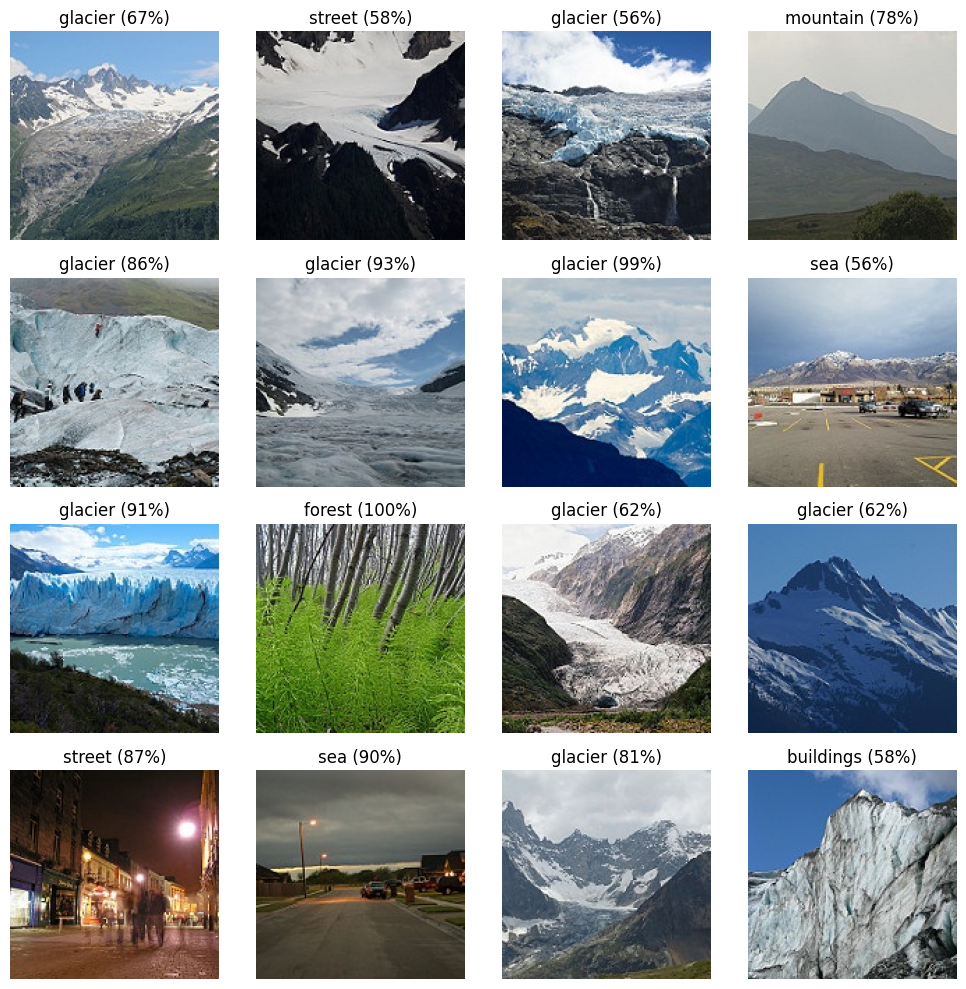

In [ ]:
# Ambil 16 gambar acak
sampel = random.sample(pred_files, 16)

plt.figure(figsize=(10, 10))
for i, f in enumerate(sampel):
    img = Image.open(f).convert("RGB").resize(IMG_SIZE)
    x = np.expand_dims(np.array(img, dtype="float32"), axis=0)   # tanpa dibagi 255
    probs = cnn1_model.predict(x, verbose=0)[0]
    idx = probs.argmax()

    plt.subplot(4, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{class_names[idx]} ({probs[idx]:.0%})")
    plt.axis("off")
plt.tight_layout()
plt.show()


## 06. KONVERSI MODEL

In [ ]:
models = {"cnn1": cnn1_model, "cnn2": cnn2_model}
base = "/content/exported_model"

# label.txt dipakai bersama TFLite
for nama in models:
    os.makedirs(f"{base}/{nama}/tflite", exist_ok=True)
    with open(f"{base}/{nama}/tflite/label.txt", "w") as f:
        f.write("\n".join(class_names))


### **saved_model**

In [ ]:
for nama, model in models.items():
    model.export(f"{base}/{nama}/saved_model")
    print(nama, "-> saved_model selesai")


Saved artifact at '/content/exported_model/cnn1/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_181')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  135913532976272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135913532965328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135916938409936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135916938398224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135916938399760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135916938398032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135916938408400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135916938410128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135916992957136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135916992966928: TensorSpec(shape=(), dtype=tf.resource,

### **TFLite**

In [ ]:
for nama in models:
    converter = tf.lite.TFLiteConverter.from_saved_model(f"{base}/{nama}/saved_model")
    tflite_model = converter.convert()
    with open(f"{base}/{nama}/tflite/model.tflite", "wb") as f:
        f.write(tflite_model)
    print(nama, "-> tflite selesai")


cnn1 -> tflite selesai
cnn2 -> tflite selesai


In [ ]:
# Ekspor .zip model saved_model + tflite
!cd /content && zip -r exported_model.zip exported_model

from google.colab import files as colab_files
colab_files.download("/content/exported_model.zip")


updating: exported_model/ (stored 0%)
updating: exported_model/cnn1/ (stored 0%)
updating: exported_model/cnn1/saved_model/ (stored 0%)
updating: exported_model/cnn1/saved_model/saved_model.pb (deflated 85%)
updating: exported_model/cnn1/saved_model/variables/ (stored 0%)
updating: exported_model/cnn1/saved_model/variables/variables.data-00000-of-00001 (deflated 7%)
updating: exported_model/cnn1/saved_model/variables/variables.index (deflated 62%)
updating: exported_model/cnn1/saved_model/fingerprint.pb (stored 0%)
updating: exported_model/cnn1/saved_model/assets/ (stored 0%)
updating: exported_model/cnn1/tflite/ (stored 0%)
updating: exported_model/cnn1/tflite/label.txt (deflated 2%)
updating: exported_model/cnn1/tflite/model.tflite (deflated 7%)
updating: exported_model/cnn2/ (stored 0%)
updating: exported_model/cnn2/saved_model/ (stored 0%)
updating: exported_model/cnn2/saved_model/saved_model.pb (deflated 90%)
updating: exported_model/cnn2/saved_model/variables/ (stored 0%)
updatin

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **tfjs_model**

In [ ]:
import os, sys, tensorflow as tf
print("Python executable:", sys.executable)
print("TensorFlow version:", tf.__version__)

for nama in ["cnn1", "cnn2"]:
    p = f"exported_model/{nama}/saved_model"
    print(nama, os.path.exists(p), os.listdir(p) if os.path.exists(p) else "")

for nama in ["cnn1", "cnn2"]:
    m = tf.saved_model.load(f"exported_model/{nama}/saved_model")
    print(nama, "terbaca:", list(m.signatures.keys()))


Python executable: c:\Users\Hanna\miniconda3\envs\tfjs\python.exe
TensorFlow version: 2.15.0
cnn1 True ['assets', 'fingerprint.pb', 'saved_model.pb', 'variables']
cnn2 True ['assets', 'fingerprint.pb', 'saved_model.pb', 'variables']
cnn1 terbaca: ['serve', 'serving_default']
cnn2 terbaca: ['serve', 'serving_default']


In [ ]:
!tensorflowjs_converter \
    --input_format=tf_saved_model \
    --output_format=tfjs_graph_model \
    --saved_model_tags=serve \
    exported_model/cnn1/saved_model \
    exported_model/cnn1/tfjs_model_graph

!tensorflowjs_converter \
    --input_format=tf_saved_model \
    --output_format=tfjs_graph_model \
    --saved_model_tags=serve \
    exported_model/cnn2/saved_model \
    exported_model/cnn2/tfjs_model_graph


2026-11-04 08:53:17.986863: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

2026-11-04 08:53:23.587488: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE SSE2 SSE3 SSE4.1 SSE4.2 AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-04 08:53:23.691810: I tensorflow/core/grappler/devices.cc:75] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
2026-11-04 08:53:23.692071: I tensorflow/core/grappler/clusters/single_machine.cc:361] Starting new session
2026-11-04 08:53:25.779698: I tensorflow/cor

In [4]:
import os, json
for nama in ["cnn1", "cnn2"]:
    folder = f"exported_model/{nama}/tfjs_model_graph"
    print(nama, os.listdir(folder))
    with open(f"{folder}/model.json") as f:
        print("  format:", json.load(f)["format"])


cnn1 ['group1-shard1of3.bin', 'group1-shard2of3.bin', 'group1-shard3of3.bin', 'model.json']
  format: graph-model
cnn2 ['group1-shard1of5.bin', 'group1-shard2of5.bin', 'group1-shard3of5.bin', 'group1-shard4of5.bin', 'group1-shard5of5.bin', 'model.json']
  format: graph-model


**REQUIREMENTS.TXT COLAB**

In [ ]:
!pip freeze > "requirements.txt"
